In [1]:
import pandas as pd
import json
import re
import networkx as nx
from pyvis.network import Network
from fractions import Fraction
# Шкала Саати: 1 - рівна важливість, 3 - помірна перевага, 5 - суттєва, 7 - значна, 9 - дуже сильна.
SAATY_RI = {1: 0.0, 2: 0.0, 3: 0.58, 4: 0.90, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45}
CR_LIMIT = 0.10

def saaty_weights(names, judgments):
    n = len(names)
    idx = {k: i for i, k in enumerate(names)}
    if len(judgments) != n * (n - 1) // 2:
        raise ValueError(f"Потрібно {n * (n - 1) // 2} порівнянь, задано {len(judgments)}")
    A = [[1.0] * n for _ in range(n)]
    seen = set()
    for a, b, v, _why in judgments:
        pair = frozenset((a, b))
        if a == b or pair in seen or not 1 <= v <= 9:
            raise ValueError(f"Некоректне порівняння {a}/{b} = {v}")
        seen.add(pair)
        A[idx[a]][idx[b]], A[idx[b]][idx[a]] = float(v), 1.0 / v
    row_sums = [sum(r) for r in A]
    total = sum(row_sums)
    w = [x / total for x in row_sums]
    if n > 2:
        lam = sum(sum(A[i][j] * w[j] for j in range(n)) / w[i] for i in range(n)) / n
        ci = (lam - n) / (n - 1)
        cr = ci / SAATY_RI[n]
    else:
        lam, ci, cr = float(n), 0.0, 0.0   
    return dict(zip(names, w)), lam, ci, cr

# Рівень 1: критерії 
CRIT_CRITERIA = ['SEV', 'CONF']
CRIT_JUDGMENTS = [
    ('SEV', 'CONF', 3, "Клас наслідку визначає масштаб шкоди, а підтвердження лише показує, чи шкода "
                       "відбулась: тяжкість помірно важливіша за підтвердженість"),
]
# Рівень 2: класи тяжкості наслідку 
SEV_CLASSES = ['phys', 'destr', 'ransom', 'exfil', 'access', 'malware', 'low']
SEV_LABELS = {
    'phys': 'фізичний вплив (збій технологічних процесів, знеструмлення)',
    'destr': 'знищення даних (wiper)',
    'ransom': 'програмне вимагання',
    'exfil': 'витік даних',
    'access': 'несанкціонований доступ',
    'malware': 'шкідливе ПЗ',
    'low': 'обмежений вплив (DDoS, дефейсмент, фішинг, інформаційні операції, інше)',
}
SEV_JUDGMENTS = [
    ('phys', 'destr', 2, "Обидва наслідки незворотні, але фізичний вплив зачіпає людей і безперервність послуг"),
    ('phys', 'ransom', 3, "Вимагання зазвичай зворотне (резервні копії, ключ), фізичний вплив - ні"),
    ('phys', 'exfil', 4, "Витік не зупиняє процеси та не загрожує безпеці людей"),
    ('phys', 'access', 6, "Доступ лише створює можливість шкоди, фізичний вплив - уже реалізована шкода"),
    ('phys', 'malware', 7, "Ураження робочих станцій значно менш тяжке за збій фізичних процесів"),
    ('phys', 'low', 9, "Абсолютна перевага над наслідками без реального збитку"),
    ('destr', 'ransom', 2, "Знищення незворотне, за вимагання є шанс відновлення"),
    ('destr', 'exfil', 3, "Втрата даних суттєвіша за порушення конфіденційності: у власника дані лишаються"),
    ('destr', 'access', 5, "Доступ - можливість, знищення - реалізований збиток"),
    ('destr', 'malware', 6, "Знищення даних значно тяжче за наявність шкідливого ПЗ в системі"),
    ('destr', 'low', 8, "Знищення даних майже абсолютно перевищує наслідки обмеженого впливу"),
    ('ransom', 'exfil', 2, "Вимагання порушує доступність і вимагає викупу, витік не зупиняє роботу"),
    ('ransom', 'access', 3, "Шифрування є реалізованою шкодою, доступ - лише можливістю"),
    ('ransom', 'malware', 4, "Вимагання - наслідок, який завдає прямих збитків; malware - засіб"),
    ('ransom', 'low', 6, "Вимагання суттєво тяжче за DDoS, дефейсмент і фішинг"),
    ('exfil', 'access', 2, "Реалізований витік тяжчий за потенційну можливість"),
    ('exfil', 'malware', 3, "Витік - підтверджена шкода, ураження шкідливим ПЗ - ще ні"),
    ('exfil', 'low', 5, "Витік даних суттєво перевищує наслідки обмеженого впливу"),
    ('access', 'malware', 2, "Закріплення в мережі дає контроль над системами, malware зазвичай локальне"),
    ('access', 'low', 3, "Несанкціонований доступ помірно тяжчий за DDoS, дефейсмент і фішинг"),
    ('malware', 'low', 2, "Зараження систем трохи тяжче за короткочасні або лише інформаційні наслідки"),
]

CRIT_W, _lam1, _ci1, CRIT_CR = saaty_weights(CRIT_CRITERIA, CRIT_JUDGMENTS)
SEV_W, SEV_LAMBDA, SEV_CI, SEV_CR = saaty_weights(SEV_CLASSES, SEV_JUDGMENTS)
if SEV_CR >= CR_LIMIT:
    raise ValueError(f"Матриця тяжкості неузгоджена: CR = {SEV_CR:.3f} >= {CR_LIMIT}")
X_SEV = {k: v / max(SEV_W.values()) for k, v in SEV_W.items()}   # нормування до [0; 1]

SEVERITY_CLASS = {
    'physical_impact': 'phys', 'data_destruction': 'destr', 'ransomware': 'ransom',
    'data_exfiltration': 'exfil', 'unauthorized_access': 'access',
    'malware': 'malware', 'malware_distribution': 'malware',
}

def severity_class(event_type):
    return SEVERITY_CLASS.get(str(event_type).lower(), 'low')

def calculate_criticality_score(event_type: str, is_confirmed: bool) -> float:
    c = CRIT_W['SEV'] * X_SEV[severity_class(event_type)] + CRIT_W['CONF'] * (1.0 if is_confirmed else 0.0)
    return round(10 * c, 1)

def print_saaty_report():
    print("МЕТОД СААТІ: ваги критичності")
    print(f"  Критерії: SEV = {CRIT_W['SEV']:.3f}, CONF = {CRIT_W['CONF']:.3f} (матриця 2x2, завжди узгоджена)")
    print(f"  Клас тяжкості (λmax = {SEV_LAMBDA:.3f}, CI = {SEV_CI:.3f}, CR = {SEV_CR:.3f}):")
    for k in SEV_CLASSES:
        print(f"    {k:<8} w = {SEV_W[k]:.3f}   x = {X_SEV[k]:.2f}   {SEV_LABELS[k]}")

def print_matrix(names, judgments):
    n = len(names)
    idx = {k: i for i, k in enumerate(names)}
    A = [[Fraction(1)] * n for _ in range(n)]
    for a, b, v, _why in judgments:
        A[idx[a]][idx[b]], A[idx[b]][idx[a]] = Fraction(v), Fraction(1, v)
    print(f"{'':>8}" + "".join(f"{k:>8}" for k in names) + f"{'сума':>8}")
    for k, row in zip(names, A):
        print(f"{k:>8}" + "".join(f"{str(x):>8}" for x in row) + f"{float(sum(row)):>8.2f}")

print_saaty_report()
print_matrix(SEV_CLASSES, SEV_JUDGMENTS)
def clean_threat_actor(actor):
    if not actor or str(actor).lower() in ['nevdo_mo', 'nevіdомо', 'зловмисник', 'зловмисники']:
        return 'невідомо'
    match = re.search(r'(UAC-\d{4})', str(actor), re.IGNORECASE)
    if match: return match.group(1).upper()
    return str(actor)

CHANGELOG = []  

def log_change(ev_id, field, old, new):
    if old != new:
        CHANGELOG.append((ev_id, field, old, new))


SNAKE_RE = re.compile(r'^[a-z]+(?:_[a-z]+)+$')
def drop_snake_case(value, fallback='невідомо'):
    return fallback if SNAKE_RE.match(str(value).strip()) else value


TYPE_KEYWORDS = {  
    'defense': ['військов', 'оборон', 'сил безпеки'],
    'telecom': ['телеком', 'оператор', 'провайдер'],
    'finance': ['фінанс', 'банк'],
    'justice': ['судов', 'нотаріат', 'юстиц'],
    'healthcare': ['медичн', "охорони здоров"],
    'industrial': ['промисл', 'завод'],
    'media': ['медіа', 'змі'],
    'government': ['державн', 'самоврядуван', 'міністерств'],
}
def type_to_sector(type_label):
    low = str(type_label).lower()
    for sector, kws in TYPE_KEYWORDS.items():
        if any(k in low for k in kws):
            return sector
    return None

def split_target_type(raw_type, sector):
    parts = [p.strip() for p in str(raw_type).split(',') if p.strip()]
    mapped = [type_mapping.get(p, p) for p in parts]
    if len(mapped) <= 1:
        return (mapped[0] if mapped else raw_type), []
    # основний тип — той, що узгоджується з полем sector, інакше перший
    primary = next((m for m in mapped if type_to_sector(m) == sector), mapped[0])
    return primary, mapped


ENTITY_SECTOR_KEYWORDS = {
    'energy': ['укренерго', 'дтек', 'обленерго'],
    'telecom': ['ukr.net', 'київстар', 'vodafone', 'lifecell', 'укртелеком'],
    'finance': ['приватбанк', 'ощадбанк', 'нбу', 'monobank', 'монобанк'],
    'transport': ['укрзалізниц', 'укрпошт', 'нова пошта', 'аеропорт'],
    'defense': ['міноборони', 'зсу', 'генштаб', 'сили оборони'],
    'justice': ['печерськ', 'нотаріат'],
    'media': ['укрінформ', 'тсн', 'телеканал'],
}
def sector_from_entity(entity):
    low = str(entity).lower()
    for sector, kws in ENTITY_SECTOR_KEYWORDS.items():
        if any(re.search(r'\b' + re.escape(k), low) for k in kws):
            return sector
    return None


WEAK_EVENT_TYPES = {'malware', 'unauthorized_access', 'other'}
UPGRADE_RULES = [  
    ('physical_impact',   ['знеструмлен', 'зупинк', 'блекаут', 'scada', 'асутп']),
    ('data_destruction',  ['знищен', 'затиранн', 'wiper', 'деструктив']),
    ('ransomware',        ['шифруван', 'вимагання', 'викуп']),
    ('data_exfiltration', ['викрад', 'ексфільтрац', 'витік']),
]
def refine_event_type(event_type, is_confirmed, impact_text):
    if not is_confirmed or event_type not in WEAK_EVENT_TYPES:
        return event_type
    low = str(impact_text).lower()
    for new_type, stems in UPGRADE_RULES:
        if any(st in low for st in stems):
            return new_type
    return event_type

# Словники 
entity_mapping = {
    'ua-gov[.]cloud': 'невідомо', 'ukraer': 'невідомо', 'UAC-0180': 'невідомо',
    'UAC-0173': 'невідомо', 'RemcosRAT servers': 'невідомо', 'Тківський обслуговування': 'невідомо'
}

type_mapping = {
    'військове формування': 'сили безпеки та оборони',
    'EOM of defense industry employees and Ukrainian Armed Forces personnel': 'сили безпеки та оборони',
    'government': 'державна установа', 'фінанси': 'фінансова установа',
    'телефонізаційний оператор': 'телекомунікаційний оператор', 'Incident Report': 'невідомо',
    'Network': 'невідомо', 'domain': 'невідомо', 'Domain Name': 'невідомо', 'servers': 'невідомо',
    'cyber threat actor': 'невідомо', "комп'ютерний системи": 'невідомо',
    'постачальник рішень АСУТП': 'промислове підприємство', 'оборонно-промисловий комплекс': 'промислове підприємство',
    'индустріальна установа': 'промислове підприємство', 'школа/університет': 'навчальний заклад',
    'Individuals': 'громадяни', 'diplomatic institution': 'дипломатична установа',
    'комунікальне підприємство': 'комунальне підприємство', 'Corporate network': 'комерційна організація',
    'government_agency': 'державна установа', 'individuals_and_general_public': 'громадяни',
    'комуналка': 'комунальне підприємство', 'промисловий завод': 'промислове підприємство',
    'оборонне військове формування': 'сили безпеки та оборони',
    'Individual/Company': 'комерційна організація', 'компанія': 'комерційна організація', 'ІТ компанія': 'комерційна організація'
}


SECTOR_LABELS = {
    'energy': 'Паливно-енергетичний сектор',
    'telecom': 'Цифрові технології',            
    'finance': 'Фінансова та банківська діяльність',
    'transport': 'Транспорт і пошта',
    'government': 'Державна влада',
    'defense': 'Сектор оборони',                
    'justice': 'Правосуддя',
    'healthcare': "Охорона здоров'я",
    'water_supply': 'Системи життєзабезпечення',  
    'industrial': 'Промисловість',
    'media': 'Інформаційний сектор',
    'unknown': 'Сектор невідомо'
}

def get_sector_label(sector):
    key = str(sector).strip().lower() if sector is not None else 'unknown'
    return SECTOR_LABELS.get(key, 'сектор невідомо')


events = []
original_data = []

with open('enriched_events.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        ev = json.loads(line)
        events.append(ev)
        if 'llm_extraction' in ev:
            original_data.append(dict(ev['llm_extraction']))

df_before = pd.DataFrame(original_data)


cleaned_data = []

for event in events:
    if 'llm_extraction' in event:
        ext = event['llm_extraction']
        ev_id = event.get('event_id', '?')
        before = dict(ext)
        
        if ext.get('target_entity') == 'Banking Institution':
            ext['target_type'] = 'фінансова установа'
            ext['target_entity'] = 'Банківська установа'  
        elif ext.get('target_entity') == 'Нотаріат України':
            ext['target_type'] = 'державна установа'
            ext['target_entity'] = 'Нотаріат України'
        elif ext.get('target_entity') == 'Укрзалізниця':
            ext['target_type'] = 'державна установа'
            ext['target_entity'] = 'Укрзалізниця'
        elif ext.get('target_entity') in ['Military personnel', 'ЕОМ представника Сил оборони України', 'Сил оборони України']:
            ext['target_type'] = 'сили безпеки та оборони'
            ext['target_entity'] = 'Сили оборони України'
        elif ext.get('target_entity') == 'UAC (Український світовий конґрес)':
            ext['target_entity'] = 'Світовий конґрес українців'
        elif str(ext.get('target_entity')).lower() in ['державні органи україни', 'державна установа']:
            ext['target_type'] = 'державна установа'
            ext['target_entity'] = 'невідомо'  
        else:
            if ext.get('target_entity') in entity_mapping:
                ext['target_entity'] = entity_mapping[ext['target_entity']]
                
        
        ext['target_entity'] = drop_snake_case(ext.get('target_entity', 'невідомо'))
        ext['confirmed_impact'] = drop_snake_case(ext.get('confirmed_impact', 'невідомо'))

        
        ent_sector = sector_from_entity(ext.get('target_entity'))
        if ent_sector:
            ext['sector'] = ent_sector

        
        primary, all_types = split_target_type(ext.get('target_type', 'невідомо'), ext.get('sector'))
        ext['target_type'] = drop_snake_case(primary)
        if all_types:
            ext['target_types_all'] = all_types

        ext['threat_actor'] = clean_threat_actor(ext.get('threat_actor'))

        
        is_conf = ext.get('is_impact_confirmed', False)
        imp_text = ext.get('confirmed_impact', '')

        
        old_type = ext.get('event_type', 'other')
        e_type = refine_event_type(old_type, is_conf, imp_text)
        ext['event_type'] = e_type

        old_score = calculate_criticality_score(old_type, is_conf)
        new_score = calculate_criticality_score(e_type, is_conf)
        
        
        ext['criticality_score'] = new_score
        if 'preliminary_impact_score' in ext:
            del ext['preliminary_impact_score']
        
        for fld in ('target_entity', 'target_type', 'sector', 'event_type', 'confirmed_impact'):
            log_change(ev_id, fld, before.get(fld), ext.get(fld))
        log_change(ev_id, 'criticality_score (правило)', old_score, new_score)
        
        cleaned_data.append(ext)

df_after = pd.DataFrame(cleaned_data)

columns_to_show = ['target_entity', 'target_type']

for col in columns_to_show:
    print(f"\n{'='*60}")
    print(f"ПОРІВНЯННЯ ДЛЯ ПОЛЯ: {col.upper()}")
    print(f"{'='*60}")
    
    print("\nДО ОЧИЩЕННЯ (Топ 10):")
    print("-" * 30)
    print(df_before[col].value_counts().head(10))
    
    print("\nПІСЛЯ ОЧИЩЕННЯ (Топ 10):")
    print("-" * 30)
    print(df_after[col].value_counts().head(10))

print(f"\n{'='*60}")
print("ЖУРНАЛ ЗМІН")
print(f"{'='*60}")
if CHANGELOG:
    print(pd.Series([c[1] for c in CHANGELOG]).value_counts().to_string())
    for ev_id, fld, old, new in CHANGELOG:
        if fld in ('event_type', 'sector', 'criticality_score (правило)'):
            print(f"  {ev_id}  {fld}: {old} -> {new}")
else:
    print("Змін немає")

output_filename = 'cleaned_events.jsonl'
with open(output_filename, 'w', encoding='utf-8') as f:
    for event in events:
        f.write(json.dumps(event, ensure_ascii=False) + '\n')

print(f"\nДані очищено та збережено у '{output_filename}'!")

print("Завантаження даних та побудова графа...")

graph_events = []
with open('cleaned_events.jsonl', 'r', encoding='utf-8') as f:
    for line in f:
        graph_events.append(json.loads(line)['llm_extraction'])

df_graph = pd.DataFrame(graph_events)
df_graph = df_graph[df_graph['threat_actor'] != 'невідомо']

G = nx.Graph()
edge_criticality_map = {}  
edge_counter = 0

for _, row in df_graph.iterrows():
    actor = row['threat_actor']
    target_type = row['target_type']
    sector_label = get_sector_label(row.get('sector'))
    sector_node = f"SECTOR::{sector_label}"
    target_entity = row['target_entity']
    
    vector = row.get('attack_vector', 'unknown')
    e_type = row.get('event_type', 'unknown')
    criticality = row.get('criticality_score', 1) 
    
    G.add_node(actor, node_type='actor')
    G.add_node(sector_node, node_type='sector', label=sector_label)
    
    incident_detail = f"• [{e_type}] Вектор: {vector} | Тип цілі: {target_type} | Бал критичності: {criticality}/10"
    
    if target_entity == 'невідомо':
        if G.has_edge(actor, sector_node):
            G[actor][sector_node]['weight'] += 1
            G[actor][sector_node]['criticalities'].append(criticality) 
            G[actor][sector_node]['details'].append(incident_detail)
        else:
            G.add_edge(actor, sector_node, weight=1, 
                       criticalities=[criticality], details=[incident_detail])
    else:
        G.add_node(target_entity, node_type='entity')
        
        if G.has_edge(actor, target_entity):
            G[actor][target_entity]['weight'] += 1
            G[actor][target_entity]['criticalities'].append(criticality)
            G[actor][target_entity]['details'].append(incident_detail)
        else:
            G.add_edge(actor, target_entity, weight=1, 
                       criticalities=[criticality], details=[incident_detail])
            
        if not G.has_edge(target_entity, sector_node):
            G.add_edge(target_entity, sector_node, weight=1, is_structural=True)

net = Network(height='100vh', width='100%', bgcolor='#1a1a1a', font_color='white', notebook=True, cdn_resources='remote')
net.force_atlas_2based(spring_length=150, overlap=0)

for node, node_attrs in G.nodes(data=True):
    degree = G.degree(node)
    n_type = node_attrs.get('node_type')
    display_label = node_attrs.get('label', node)
    
    if n_type == 'actor':
        color, size, title = '#ff4b4b', 15 + (degree * 5), "Хакерська група (APT)"
    elif n_type == 'sector':
        color, size, title = '#4b8bff', 20 + (degree * 4), "Сектор критичної інфраструктури"
    elif n_type == 'entity':
        color, size, title = '#10b981', 15 + (degree * 3), "Конкретна організація"
        
    net.add_node(node, label=display_label, color=color, size=size, title=title)

for u, v, edge_attrs in G.edges(data=True):
    edge_counter += 1
    edge_id = f"edge_{edge_counter}"
    
    if edge_attrs.get('is_structural'):
        net.add_edge(u, v, id=edge_id, value=1, title="Належність до сектора", color='#444444', dashes=True)
    else:
        w = edge_attrs.get('weight', 1)
        criticalities = edge_attrs.get('criticalities', [1])
        
        max_criticality = max(criticalities)
        details_list = edge_attrs.get('details', [])
        
        edge_criticality_map[edge_id] = max_criticality
        
        formatted_details = "\n".join(details_list)
        
        tooltip = (f"Кількість інцидентів: {w}\n"
                   f"Макс. бал критичності: {max_criticality} / 10\n"
                   f"-----------------------------------\n"
                   f"Деталі інцидентів:\n{formatted_details}")
                   
        if max_criticality >= 8:
            edge_color = '#ff0000'
        elif max_criticality >= 5:
            edge_color = '#ffa500'
        else:
            edge_color = '#666666'
            
        net.add_edge(u, v, id=edge_id, value=w, title=tooltip, color=edge_color)

graph_filename = "final_diploma_graph.html"
net.show(graph_filename)

with open(graph_filename, 'r', encoding='utf-8') as f:
    html_content = f.read()


edge_criticality_json = json.dumps(edge_criticality_map)


control_panel_code = """
<div id="legend-panel" style="position: fixed; top: 20px; left: 20px; background: rgba(30,30,30,0.92); padding: 15px 20px; border-radius: 10px; color: #fff; z-index: 9999; font-family: Arial, sans-serif; box-shadow: 0 4px 15px rgba(0,0,0,0.5); border: 1px solid #444; width: 280px; backdrop-filter: blur(5px);">
    <h3 style="margin-top: 0; font-size: 15px; border-bottom: 1px solid #555; padding-bottom: 8px; color: #4b8bff;">Легенда та Фільтри</h3>
    
    <div style="margin-bottom: 12px; font-size: 12px; line-height: 1.5;">
        <b>Вузли:</b><br>
        <div style="display: flex; align-items: center; margin-top: 3px;"><span style="width: 10px; height: 10px; background: #ff4b4b; border-radius: 50%; display: inline-block; margin-right: 8px;"></span> Хакерська група (APT)</div>
        <div style="display: flex; align-items: center; margin-top: 3px;"><span style="width: 10px; height: 10px; background: #4b8bff; border-radius: 50%; display: inline-block; margin-right: 8px;"></span> Сектор критичної інфраструктури</div>
        <div style="display: flex; align-items: center; margin-top: 3px;"><span style="width: 10px; height: 10px; background: #10b981; border-radius: 50%; display: inline-block; margin-right: 8px;"></span> Конкретна організація</div>
    </div>

    <div style="margin-bottom: 12px; font-size: 12px; line-height: 1.5;">
        <b>Рівень критичності зв'язків (за макс. балом):</b><br>
        <div style="display: flex; align-items: center; margin-top: 3px;"><span style="width: 18px; height: 3px; background: #ff0000; display: inline-block; margin-right: 8px;"></span> Критичний (>= 8)</div>
        <div style="display: flex; align-items: center; margin-top: 3px;"><span style="width: 18px; height: 3px; background: #ffa500; display: inline-block; margin-right: 8px;"></span> Середній (5 - 7.9)</div>
        <div style="display: flex; align-items: center; margin-top: 3px;"><span style="width: 18px; height: 3px; background: #666666; display: inline-block; margin-right: 8px;"></span> Низький (< 5)</div>
        <div style="display: flex; align-items: center; margin-top: 3px;"><span style="width: 18px; height: 2px; border-top: 2px dashed #444; display: inline-block; margin-right: 8px;"></span> Структурний зв'язок</div>
    </div>

    <div style="font-size: 12px;">
        <label for="criticalityFilter" style="display: block; margin-bottom: 5px;"><b>Фільтр мін. балу критичності:</b></label>
        <select id="criticalityFilter" onchange="applyCriticalityFilter()" style="width: 100%; background: #222; color: #fff; border: 1px solid #555; padding: 6px; border-radius: 4px; cursor: pointer; outline: none;">
            <option value="0">Усі зв'язки (0+)</option>
            <option value="1">Від 1 і вище</option>
            <option value="2">Від 2 і вище</option>
            <option value="3">Від 3 і вище</option>
            <option value="4">Від 4 і вище</option>
            <option value="5">Від 5 і вище (Середній)</option>
            <option value="6">Від 6 і вище</option>
            <option value="7">Від 7 і вище</option>
            <option value="8">Від 8 і вище (Критичний)</option>
            <option value="9">Від 9 і вище</option>
            <option value="10">Лише рівень 10</option>
        </select>
    </div>
</div>

<script type="text/javascript">
    var edgeCriticalities = __EDGE_CRITICALITY_JSON__;

    function applyCriticalityFilter() {
        var minCrit = parseFloat(document.getElementById('criticalityFilter').value);
        var allEdges = edges.get();
        
        var updates = [];
        allEdges.forEach(function(edge) {
            if (edge.id in edgeCriticalities) {
                var crit = edgeCriticalities[edge.id];
                if (crit < minCrit) {
                    updates.push({id: edge.id, hidden: true});
                } else {
                    updates.push({id: edge.id, hidden: false});
                }
            }
        });
        edges.update(updates);
    }
</script>
</body>
"""


control_panel_code = control_panel_code.replace('__EDGE_CRITICALITY_JSON__', edge_criticality_json)
html_content = html_content.replace("</body>", control_panel_code)

with open(graph_filename, 'w', encoding='utf-8') as f:
    f.write(html_content)

print(f"\nГраф збережено у файл '{graph_filename}'")

МЕТОД СААТІ: ваги критичності
  Критерії: SEV = 0.750, CONF = 0.250 (матриця 2x2, завжди узгоджена)
  Клас тяжкості (λmax = 7.221, CI = 0.037, CR = 0.028):
    phys     w = 0.319   x = 1.00   фізичний вплив (збій технологічних процесів, знеструмлення)
    destr    w = 0.254   x = 0.80   знищення даних (wiper)
    ransom   w = 0.168   x = 0.53   програмне вимагання
    exfil    w = 0.120   x = 0.38   витік даних
    access   w = 0.072   x = 0.23   несанкціонований доступ
    malware  w = 0.044   x = 0.14   шкідливе ПЗ
    low      w = 0.024   x = 0.08   обмежений вплив (DDoS, дефейсмент, фішинг, інформаційні операції, інше)
            phys   destr  ransom   exfil  access malware     low    сума
    phys       1       2       3       4       6       7       9   32.00
   destr     1/2       1       2       3       5       6       8   25.50
  ransom     1/3     1/2       1       2       3       4       6   16.83
   exfil     1/4     1/3     1/2       1       2       3       5   12.08
  ac

Готово! Гістограму збережено у файл: histogram_criticality.png


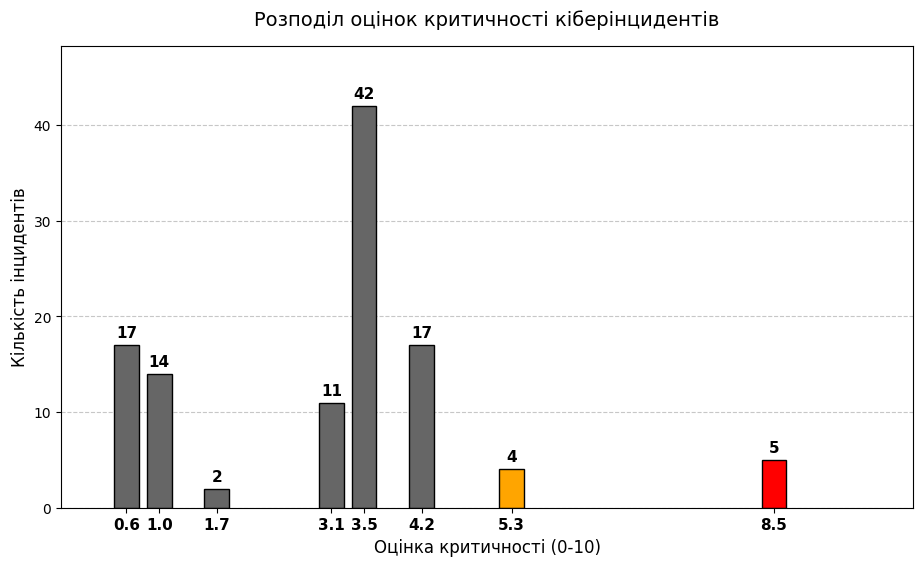

In [2]:
import json
import os
import pandas as pd
import matplotlib.pyplot as plt


def plot_criticality_histogram(input_file="cleaned_events.jsonl", output_file="histogram_criticality.png"):
    if not os.path.exists(input_file):
        print(f"Помилка: Файл {input_file} не знайдено.")
        return

    scores = []
    with open(input_file, 'r', encoding='utf-8') as f:
        for line in f:
            try:
                event = json.loads(line)
                if 'llm_extraction' in event and 'criticality_score' in event['llm_extraction']:
                    scores.append(event['llm_extraction']['criticality_score'])
            except json.JSONDecodeError:
                continue

    if not scores:
        print("Помилка: Не знайдено жодної оцінки критичності у файлі.")
        return

    df = pd.DataFrame(scores, columns=['criticality_score'])
    criticality_counts = df['criticality_score'].value_counts().sort_index()

    colors = ['#ff0000' if s >= 8 else '#ffa500' if s >= 5 else '#666666'
              for s in criticality_counts.index]

    plt.figure(figsize=(11, 6))
    bars = plt.bar(criticality_counts.index, criticality_counts.values, width=0.3,
                   color=colors, edgecolor='black', zorder=2)

    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.5, int(yval),
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

    plt.title('Розподіл оцінок критичності кіберінцидентів', fontsize=14, pad=15)
    plt.xlabel('Оцінка критичності (0-10)', fontsize=12)
    plt.ylabel('Кількість інцидентів', fontsize=12)

    plt.xticks(criticality_counts.index, [f"{s:.1f}" for s in criticality_counts.index],
               fontsize=11, fontweight='bold')
    plt.xlim(-0.2, 10.2)
    plt.ylim(0, criticality_counts.values.max() * 1.15)   
    plt.grid(axis='y', linestyle='--', alpha=0.7, zorder=1)

    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    print(f"Готово! Гістограму збережено у файл: {output_file}")
    plt.show()


plot_criticality_histogram()